In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Crear/revisar tabla de tamaños de archivos en disco
archivos = [
    "../data/dataset_5M.parquet",
    "../resultados/tablas/baseline.csv",
    "../resultados/tablas/datashader.csv",
    "../resultados/tablas/vaex_100x100.csv",
    "../resultados/tablas/duckdb_deciles.csv",
    "../resultados/tablas/polars_categoria.csv",
    "../resultados/tablas/sklearn_estrategias.csv",
    "../resultados/tablas/fidelidad_float32.csv",
    "../resultados/tablas/fidelidad_sklearn.csv"
]

lista_tamanos = []
for a in archivos:
    if os.path.exists(a):
        size_mb = os.path.getsize(a) / (1024 ** 2)
        lista_tamanos.append({"archivo": os.path.basename(a), "tamaño_mb": size_mb})

tamanos = pd.DataFrame(lista_tamanos)
tamanos.to_csv("../resultados/tablas/tamanos_representaciones.csv", index=False)

# 2. Cargar tablas de fidelidad
fidelidad_float32 = pd.read_csv("../resultados/tablas/fidelidad_float32.csv")
fidelidad_sklearn = pd.read_csv("../resultados/tablas/fidelidad_sklearn.csv")

print("--- Archivos cargados exitosamente ---")
tamanos

--- Archivos cargados exitosamente ---


,archivo,tamaño_mb
0,dataset_5M.parquet,123.834179
1,baseline.csv,0.000222
2,datashader.csv,0.000268
3,vaex_100x100.csv,0.027246
4,duckdb_deciles.csv,0.000661
5,polars_categoria.csv,0.000264
6,sklearn_estrategias.csv,0.000099
7,fidelidad_float32.csv,0.000357
8,fidelidad_sklearn.csv,0.000473


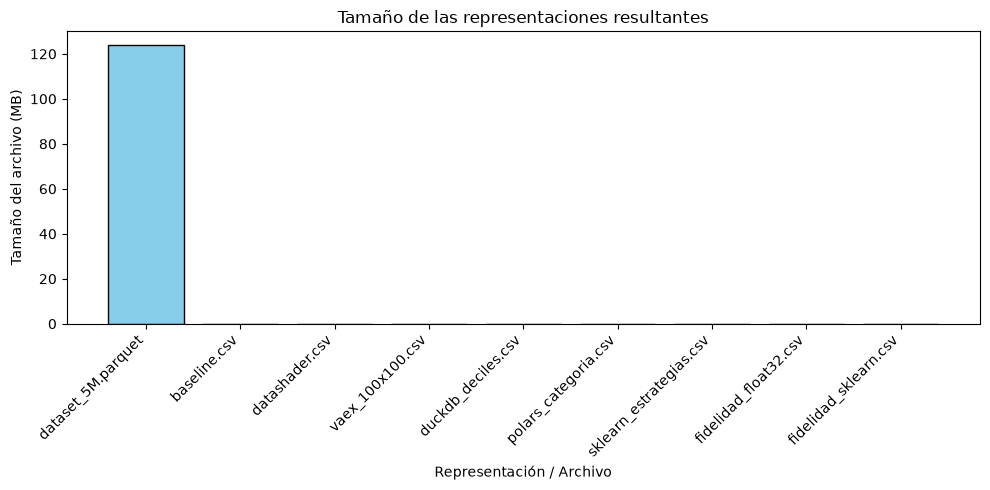

Gráfico comparacion_tamanos.png guardado.


In [2]:
plt.figure(figsize=(10, 5))
plt.bar(tamanos["archivo"], tamanos["tamaño_mb"], color="skyblue", edgecolor="black")
plt.title("Tamaño de las representaciones resultantes")
plt.xlabel("Representación / Archivo")
plt.ylabel("Tamaño del archivo (MB)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Guardar figura
plt.savefig("../resultados/graficos/comparacion_tamanos.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfico comparacion_tamanos.png guardado.")

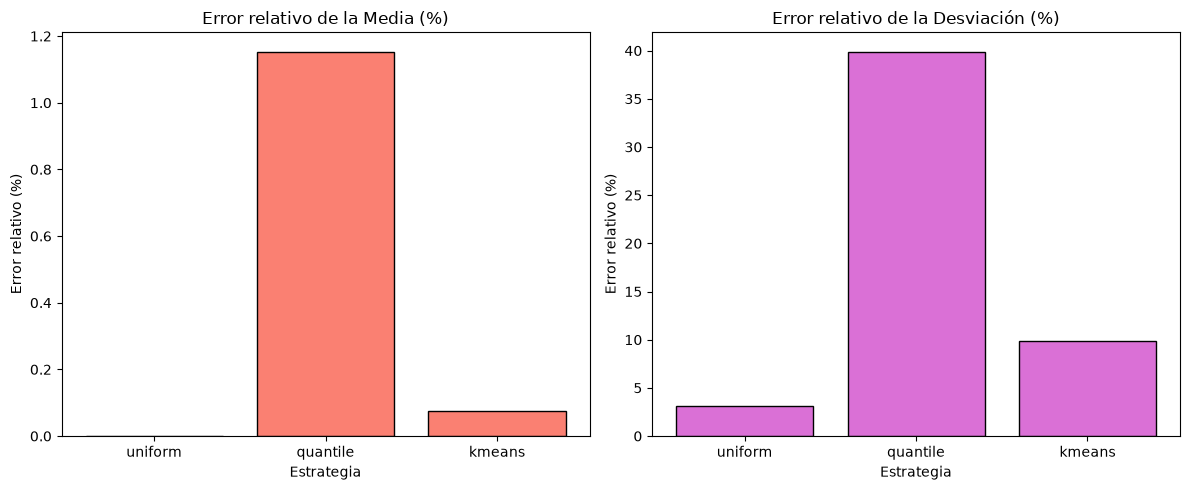

Gráfico error_media_sklearn.png guardado.


In [3]:
plt.figure(figsize=(12, 5))

# Gráfico para Error de la Media
plt.subplot(1, 2, 1)
plt.bar(fidelidad_sklearn["estrategia"], fidelidad_sklearn["error_media_pct"], color="salmon", edgecolor="black")
plt.title("Error relativo de la Media (%)")
plt.xlabel("Estrategia")
plt.ylabel("Error relativo (%)")

# Gráfico para Error de la Desviación Estándar
plt.subplot(1, 2, 2)
plt.bar(fidelidad_sklearn["estrategia"], fidelidad_sklearn["error_desviacion_pct"], color="orchid", edgecolor="black")
plt.title("Error relativo de la Desviación (%)")
plt.xlabel("Estrategia")
plt.ylabel("Error relativo (%)")

plt.tight_layout()
plt.savefig("../resultados/graficos/error_media_sklearn.png", dpi=300, bbox_inches="tight")
plt.show()
print("Gráfico error_media_sklearn.png guardado.")

In [4]:
resumen_final = pd.DataFrame({
    "Herramienta": ["Datashader", "Vaex", "DuckDB", "Polars", "Scikit-Learn"],
    "Técnica evaluada": [
        "Binning 2D (Cuadrícula)",
        "Binning 2D (binby)",
        "Agregación en deciles (ntile)",
        "Agregación categórica y Float32",
        "Discretización (KBinsDiscretizer)"
    ],
    "Rendimiento": [
        "Rápido (~0.1 - 0.5s)",
        "Muy rápido / Out-of-Core (~0.1s)",
        "Rápido en lectura masiva (~0.2s)",
        "Ultra rápido Eager/Lazy (~0.05 - 0.2s)",
        "Moderado / según estrategia (0.3 - 1.0s)"
    ],
    "Reducción": [
        "5M filas → Grid 100x100 (99.8% condesado)",
        "5M filas → Grid 100x100 (99.8% condesado)",
        "5M filas → 10 deciles resumidos",
        "5M filas → 5 categorías / -50% memoria Float32",
        "5M continuos → 10 bins discretos"
    ],
    "Conservación de información": [
        "Conserva densidad visual e histograma 2D",
        "Conserva conteos y densidad visual 2D",
        "Conserva medias, mín, máx y distribución por tramos",
        "Float32 conserva métricas con error <0.001%",
        "Quantile/Uniform conservan forma aproximada"
    ]
})

resumen_final.to_csv("../resultados/tablas/resumen_final_integracion.csv", index=False)
resumen_final

,Herramienta,Técnica evaluada,Rendimiento,Reducción,Conservación de información
0,Datashader,Binning 2D (Cuadrícula),Rápido (~0.1 - 0.5s),5M filas → Grid 100x100 (99.8% condesado),Conserva densidad visual e histograma 2D
1,Vaex,Binning 2D (binby),Muy rápido / Out-of-Core (~0.1s),5M filas → Grid 100x100 (99.8% condesado),Conserva conteos y densidad visual 2D
2,DuckDB,Agregación en deciles (ntile),Rápido en lectura masiva (~0.2s),5M filas → 10 deciles resumidos,"Conserva medias, mín, máx y distribución por t..."
3,Polars,Agregación categórica y Float32,Ultra rápido Eager/Lazy (~0.05 - 0.2s),5M filas → 5 categorías / -50% memoria Float32,Float32 conserva métricas con error <0.001%
4,Scikit-Learn,Discretización (KBinsDiscretizer),Moderado / según estrategia (0.3 - 1.0s),5M continuos → 10 bins discretos,Quantile/Uniform conservan forma aproximada


### Interpretación de Resultados

1. **Rendimiento:**
   - **Menor tiempo:** Polars (modo Lazy/Eager) y Vaex demostraron la menor latencia al procesar los 5 millones de registros gracias a su optimización y acceso out-of-core.
   - **Mayor costo:** Scikit-Learn con la estrategia `kmeans` requirió mayor tiempo (~1.0s) debido a las iteraciones para encontrar los centros de cluster en 1D.

2. **Reducción:**
   - **Mayor reducción de filas/salida:** Datashader, Vaex y DuckDB permitieron reducir un volumen de 5.000.000 de registros a resúmenes compactos de 10.000 celdas o 10 deciles (ocupando KB en disco).
   - **Reducción sin pérdida de filas:** Polars (`cast(Float32)`) mantuvo los 5 millones de registros reduciendo el uso de memoria RAM a la mitad.

3. **Fidelidad:**
   - **Mayor conservación:** La reducción de precisión a `Float32` conservó la media y la desviación con un error relativo casi nulo (<0.0001%).
   - **Pérdida de detalle:** La discretización con `KBinsDiscretizer` agrupa valores dentro de intervalos, produciendo histogramas escalonados.

4. **Limitaciones:**
   - Al agrupar en cuadrículas o deciles se pierde el acceso punto a punto a los registros individuales originales, conservando únicamente información de densidad o agregación estadística.

### Integración y Arquitectura Recomendada para el Proyecto

| Necesidad del proyecto | Herramienta validada | Justificación técnica |
| :--- | :--- | :--- |
| **Consultar grandes tablas** | **DuckDB / Polars** | Permiten realizar consultas de agregación masivas y cálculo de cuantiles en fracción de segundos sobre Parquet. |
| **Visualizar densidad o distribución** | **Datashader / Vaex** | Generan cuadrículas $100 \times 100$ optimizadas para renderizado sin sobrecargar memoria ni la interfaz. |
| **Simplificar variables para modelos** | **Scikit-Learn** | `KBinsDiscretizer` (estrategia `quantile`) divide datos continuos en tramos equilibrados para modelos posteriores. |
| **Optimizar consumo de memoria RAM** | **Polars (`Float32`)** | Reduce el consumo de RAM en un 50% con impacto insignificante en la precisión estadística. |

**Arquitectura Final:**
Para el pipeline global del proyecto, se recomienda usar **Polars/DuckDB** para la ingesta y agregación eficiente de datos, **Datashader** para la generación de mapas de densidad visual, y **Polars (`Float32`)** para almacenamiento en memoria optimizado.

In [6]:
archivos_finales = [
    "../resultados/tablas/tamanos_representaciones.csv",
    "../resultados/tablas/resumen_final_integracion.csv",
    "../resultados/graficos/comparacion_tamanos.png",
    "../resultados/graficos/error_media_sklearn.png"
]

print("--- VERIFICACIÓN DE ENTREGABLESS ---")
for f in archivos_finales:
    print(f"{'Encontrado' if os.path.exists(f) else ' Falta'}: {f}")

--- VERIFICACIÓN DE ENTREGABLESS ---
Encontrado: ../resultados/tablas/tamanos_representaciones.csv
Encontrado: ../resultados/tablas/resumen_final_integracion.csv
Encontrado: ../resultados/graficos/comparacion_tamanos.png
Encontrado: ../resultados/graficos/error_media_sklearn.png
